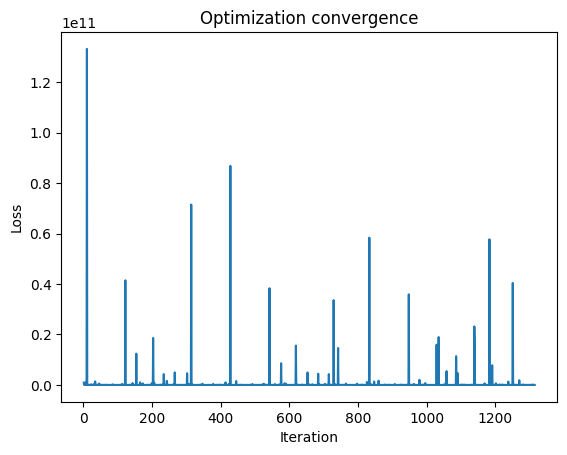

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("optimization_log_G2_BB_all.csv")

loss=df["loss"]
iterations = range(1, len(loss) + 1)

plt.plot(iterations, loss)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Optimization convergence")
plt.show()


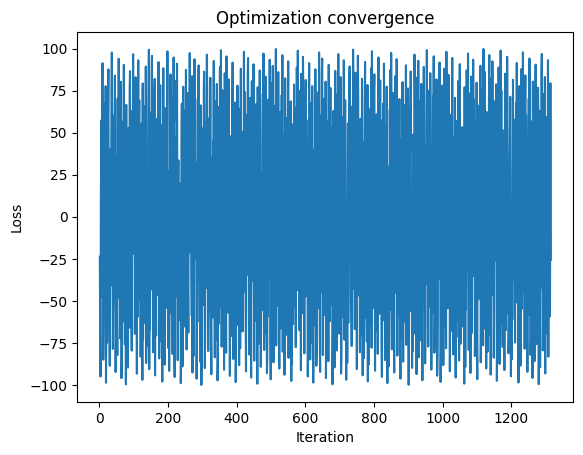

In [2]:
plt.plot(iterations, df["a"])
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Optimization convergence")
plt.show()

In [3]:
from coupling_G2_optimizer_BB_angles_perTheta import load_growth_csv, build_observed_dataset, summarize_by_time, filter_growth_below_one, mech_to_signal1, CI_to_phi_a, deriv_after_mech_change, update_Fg, run_simulation_constant_F, run_simulation_constant_F_theta_local_signal 

{'a': -52.09838944617786, 'b': 1.6454008743721715, 'c': -65.04648543165104, 'd': -51.58626559940558, 'tau_g': 83.14488211204889}


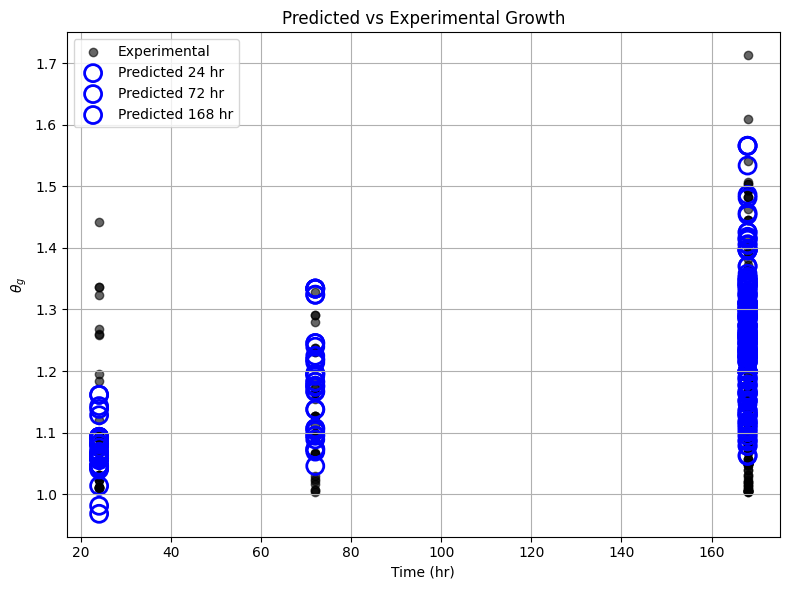

In [4]:
import numpy as np
import matplotlib.pyplot as plt

data1 = build_observed_dataset(
    "Iso_data_4_pigs.csv",
    "Iso_data_4_pigs_G1.csv",
    "Iso_data_4_pigs_G2.csv",
)
data = filter_growth_below_one(data1, tol=1e-6)
best_row = df.loc[df["loss"].idxmin()]
second_best_row = df.sort_values("loss").iloc[1]
param_loss=best_row

#     best_row["a"],
#     best_row["b"],
#     best_row["c"],
#     best_row["d"],
#     best_row["tau"]
# ])

params = {
    "a": param_loss["a"], "b": param_loss["b"],   # CI → growth in G1
    # "e": 1.0, "f": 0.0,   # CI → growth in G2
    "c": param_loss["c"], "d": param_loss["d"],   # theta_e → signaling
    # "g": 1.0, "h": 0.0,   # theta_e → signaling
    "tau_g": param_loss["tau_g"],
    # "tau_s": 0.5,
    # "tau_w": 1.0,
    # "tau_k": 1.0,
    # "gamma_k": 1.0
}

print(params)

# Target times
t_targets = [24, 72, 168]

# Storage
t_all = []
thetag_exp_all = []
thetag_model_all = []

loss = 0.0

arr = np.random.randint(0, 273, 300)

# Loop over all experiments
for i in arr:

    theta_exp  = data["G2_in_all"][i]
    thetap_exp = data["G2p_all"][i]
    thetag_exp = data["G2g_all"][i]
    thetae_exp = data["G2e_all"][i]

    t_exp = data["time_g2"][i]

    # Run model
    #     params,
    # )

    results = run_simulation_constant_F_theta_local_signal(
    params,
    lam1=theta_exp,
    lamp1=thetap_exp,
    T_end=t_exp,
    dt=0.1,
    n_theta=10,
    lam2=1.0,
    lamp2=1.0,
    prestretch_side="right",
)

    thetag_model = results[1][-1]   # still scalar: growth along theta=0 (G1)

    # Store all results
    t_all.append(t_exp)
    thetag_exp_all.append(thetag_exp)
    thetag_model_all.append(thetag_model)

# Convert to arrays
t_all = np.array(t_all)
thetag_exp_all = np.array(thetag_exp_all)
thetag_model_all = np.array(thetag_model_all)

# ==============================
# Plot
# ==============================
plt.figure(figsize=(8,6))

# All experimental points
plt.scatter(t_all, thetag_exp_all,
            color="black",
            alpha=0.6,
            label="Experimental")

# # All model predictions

# Highlight target times
for t in t_targets:
    mask = np.isclose(t_all, t)

    plt.scatter(t_all[mask],
                thetag_model_all[mask],
                s=150,
                edgecolor="blue",
                facecolor="none",
                linewidth=2,
                label=f"Predicted {t} hr")

plt.xlabel("Time (hr)")
plt.ylabel(r"$\theta_g$")
plt.title("Predicted vs Experimental Growth")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### code block for saving

This block saves:

a summary CSV with one row per experiment

an angle-profile CSV with final directional outputs for each experiment

an optional full time-angle history CSV for heatmaps and time-evolution figures

a parameters CSV

In [5]:
import pandas as pd

# =====================================================
# Save summary table for model vs experiment comparison
# =====================================================

df_summary = pd.DataFrame({
    "time_hr": t_all,
    "lambda_g_exp": thetag_exp_all,
    "lambda_g_model": thetag_model_all,
    "error": thetag_model_all - thetag_exp_all,
    "abs_error": np.abs(thetag_model_all - thetag_exp_all),
    "sq_error": (thetag_model_all - thetag_exp_all)**2
})

df_summary.to_csv("growth_model_vs_experiment.csv", index=False)

print("Saved: growth_model_vs_experiment.csv")


# =====================================================
# Save parameters used for the simulation
# =====================================================

df_params = pd.DataFrame([params])
df_params.to_csv("growth_model_parameters.csv", index=False)

print("Saved: growth_model_parameters.csv")


# =====================================================
# Save the sampled experiment indices used
# =====================================================

df_indices = pd.DataFrame({"sample_index": arr})
df_indices.to_csv("growth_model_sample_indices.csv", index=False)

print("Saved: growth_model_sample_indices.csv")


# =====================================================
# Save raw vectors individually (optional but useful)
# =====================================================

np.savetxt("vector_time_hr.csv", t_all, delimiter=",")
np.savetxt("vector_lambda_g_exp.csv", thetag_exp_all, delimiter=",")
np.savetxt("vector_lambda_g_model.csv", thetag_model_all, delimiter=",")

print("Saved individual vectors.")

Saved: growth_model_vs_experiment.csv
Saved: growth_model_parameters.csv
Saved: growth_model_sample_indices.csv
Saved individual vectors.


### More plots

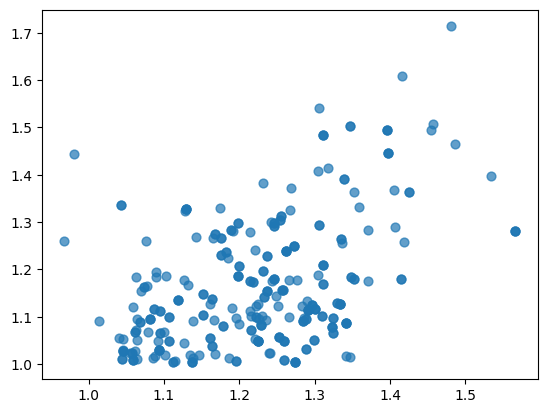

In [6]:
plt.scatter(thetag_model_all,
                thetag_exp_all,
                alpha=0.7,
                s=40)

In [7]:

# -------------------------------
# GLOBAL STYLE (professional look)
# -------------------------------
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 8,
    "legend.title_fontsize": 8,
})

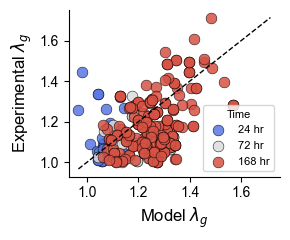

In [8]:
# # import numpy as np
# # import matplotlib.pyplot as plt

# # Ensure numpy arrays

# # Map timepoints to color indices

# # Choose a discrete colormap with 3 colors

#     x,
#     y,
# )

# # Create legend manually
#     for i, lab in enumerate(labels)
# ]

# Ensure numpy arrays
x = np.asarray(thetag_model_all)
y = np.asarray(thetag_exp_all)
arr = np.asarray(t_all)

# Map timepoints
mapping = {24: 0, 72: 1, 168: 2}
color_indices = np.array([mapping[v] for v in arr])

# Coolwarm palette (3 evenly spaced colors)
cmap = plt.get_cmap("coolwarm")
colors = [cmap(0.1), cmap(0.5), cmap(0.9)]

plt.figure(figsize=(3,2.5))

# Scatter
for i in range(3):
    mask = color_indices == i
    plt.scatter(
        x[mask],
        y[mask],
        color=colors[i],
        s=60,
        alpha=0.85,
        edgecolor="black",
        linewidth=0.4,
        label=["24 hr", "72 hr", "168 hr"][i]
    )

# Add y=x reference line
xmin = min(thetag_model_all.min(), thetag_exp_all.min())
xmax = max(thetag_model_all.max(), thetag_exp_all.max())
ax = plt.gca()  # Define ax as the current axis
ax.plot([xmin, xmax], [xmin, xmax], "--", color="black", linewidth=1)

# Labels
plt.xlabel("Model $\lambda_g$")
plt.ylabel("Experimental $\lambda_g$")

# Remove grid
plt.grid(False)

# Legend
plt.legend(title="Time", frameon=True)

# Remove top and right spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Clean layout
plt.tight_layout()
plt.savefig("figures_coupling_G2/model_vs_experiment_scatter.png", dpi=300)
plt.show()


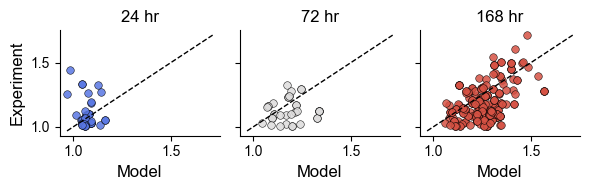

In [9]:
# # import matplotlib.pyplot as plt
# # import numpy as np

# # Unique time points (should be 24, 72, 168)

# fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)

    
    
#         thetag_model_all[idx],
#         thetag_exp_all[idx],
#     )
    

# Unique time points
time_points = [24, 72, 168]

# Coolwarm palette
cmap = plt.get_cmap("coolwarm")
colors = [cmap(0.1), cmap(0.5), cmap(0.9)]

fig, axes = plt.subplots(1, 3, figsize=(6,2), sharex=True, sharey=True)

for ax, t, col in zip(axes, time_points, colors):

    idx = np.where(np.isclose(t_all, t))[0]

    ax.scatter(
        thetag_model_all[idx],
        thetag_exp_all[idx],
        color=col,
        s=30,
        alpha=0.85,
        edgecolor="black",
        linewidth=0.4,
    )

    # 1:1 agreement line
    xmin = min(thetag_model_all.min(), thetag_exp_all.min())
    xmax = max(thetag_model_all.max(), thetag_exp_all.max())
    ax.plot([xmin, xmax], [xmin, xmax], "--", color="black", linewidth=1)

    ax.set_title(f"{t} hr")

    # Clean axes
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(False)

# Shared labels
axes[0].set_ylabel("Experiment")
for ax in axes:
    ax.set_xlabel("Model")

plt.tight_layout()
plt.savefig("figures_coupling_G2/model_vs_experiment_scatter_3.png", dpi=300)
plt.show()


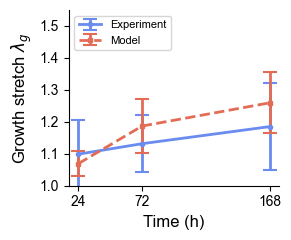

In [10]:
# # import numpy as np
# # import matplotlib.pyplot as plt

    
    

#     times, mean_exp, yerr=std_exp,
# )

#     times, mean_model, yerr=std_model,
# )

times = np.array([24, 72, 168])

mean_model = []
std_model = []
mean_exp = []
std_exp = []

for t in times:
    mask = (arr == t)
    
    mean_model.append(np.mean(x[mask]))
    std_model.append(np.std(x[mask]))
    
    mean_exp.append(np.mean(y[mask]))
    std_exp.append(np.std(y[mask]))

# Coolwarm colors
cmap = plt.get_cmap("coolwarm")
color_exp = cmap(0.15)
color_model = cmap(0.85)

plt.figure(figsize=(3,2.5))

plt.errorbar(
    times,
    mean_exp,
    yerr=std_exp,
    fmt='o-',
    color=color_exp,
    markersize=3,
    linewidth=2,
    capsize=5,
    capthick=1.5,
    label="Experiment"
)

plt.errorbar(
    times,
    mean_model,
    yerr=std_model,
    fmt='s--',
    color=color_model,
    markersize=3,
    linewidth=2,
    capsize=5,
    capthick=1.5,
    label="Model"
)

plt.xlabel("Time (h)")
plt.ylabel("Growth stretch $\\lambda_g$")
plt.xticks(times)
plt.ylim(1.0, 1.55)

# Clean axes
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.legend(frameon=True, loc="upper left")
plt.grid(False)

plt.tight_layout()
plt.savefig("figures_coupling_G2/growth_comparison_errorbar.png", dpi=300)
plt.show()

In [11]:

# -----------------------------------------
# Pick ONE experiment to inspect in angle
# -----------------------------------------
# Option 1: choose a fixed valid index directly
i = 14

# If you want to use one of the sampled indices from arr, use:

lam1_exp  = float(data["G2_in_all"][i])
lamp1_exp = float(data["G2p_all"][i])
t_exp     = 72.0

print(t_exp)

# Run theta model
#     params,
# )
results = run_simulation_constant_F_theta_local_signal(
params,
lam1=lam1_exp,
lamp1=lamp1_exp,
T_end=t_exp,
dt=0.1,
n_theta=10,
lam2=1.0,
lamp2=1.0,
prestretch_side="right",
)

t_arr    = results[0]
lamg_G1  = results[1]
lamg_arr = results[2]   # shape = (time, angle)
lam_arr  = results[3]   # total stretch vs angle
lame_arr = results[4]   # elastic stretch vs angle

# Angle vector
n_theta = lamg_arr.shape[1]
theta_vals = np.linspace(0.0, np.pi, n_theta, endpoint=False)
theta_deg = np.degrees(theta_vals)


72.0


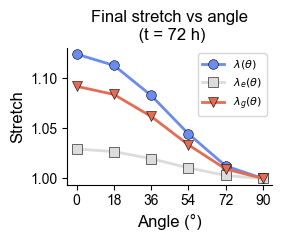

In [12]:
# # -----------------------------------------
# # Figure 1: final growth vs angle
# # -----------------------------------------

# -----------------------------------------
# Figure 2: final total and elastic stretch vs angle
# -----------------------------------------

# Colors from coolwarm
cmap = plt.get_cmap("coolwarm")
color_total = cmap(0.15)
color_elastic = cmap(0.5)
color_growth = cmap(0.85)

plt.figure(figsize=(3,2.5))

plt.plot(
    theta_deg[:-4],
    lam_arr[-1, :-4],
    marker="o",
    markersize=7,
    linewidth=2,
    color=color_total,
    markeredgecolor="black",
    markeredgewidth=0.4,
    label=r"$\lambda(\theta)$"
)

plt.plot(
    theta_deg[:-4],
    lame_arr[-1, :-4],
    marker="s",
    markersize=6.5,
    linewidth=2,
    color=color_elastic,
    markeredgecolor="black",
    markeredgewidth=0.4,
    label=r"$\lambda_e(\theta)$"
)

plt.plot(
    theta_deg[:-4],
    lamg_arr[-1, :-4],
    marker="v",
    markersize=7,
    linewidth=2,
    color=color_growth,
    markeredgecolor="black",
    markeredgewidth=0.4,
    label=r"$\lambda_g(\theta)$"
)

plt.xlabel("Angle (°)")
plt.ylabel("Stretch")

plt.xticks(theta_deg[:-4])

plt.title(
    f"Final stretch vs angle\n (t = {t_exp:.0f} h)"
)

# Clean axes
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.legend(frameon=True)
plt.grid(False)

plt.tight_layout()
plt.savefig("figures_coupling_G2/final_stretch_vs_angle_sample.png", dpi=300)
plt.show()


In [13]:

i = 0
lam1_exp  = float(data["G2_in_all"][i])
lamp1_exp = float(data["G2p_all"][i])
t_exp     = float(data["time_g2"][i])

#     params,
# )
results = run_simulation_constant_F_theta_local_signal(
params,
lam1=lam1_exp,
lamp1=lamp1_exp,
T_end=t_exp,
dt=0.1,
n_theta=18,
lam2=1.0,
lamp2=1.0,
prestretch_side="right",
)

t_arr    = results[0]
lamg_arr = results[2]

theta_vals = np.linspace(0.0, np.pi, lamg_arr.shape[1], endpoint=False)
theta_deg = np.degrees(theta_vals)

# choose early / middle / final times
idx1 = 0
idx2 = len(t_arr) // 2
idx3 = -1


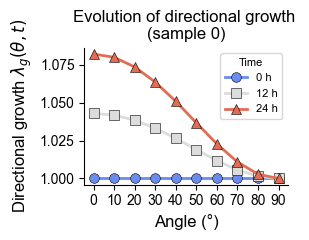

In [14]:


last = -8

# Colors from coolwarm (early → late)
cmap = plt.get_cmap("coolwarm")
color1 = cmap(0.15)
color2 = cmap(0.5)
color3 = cmap(0.85)

plt.figure(figsize=(3,2.5))

plt.plot(
    theta_deg[:last],
    lamg_arr[idx1, :last],
    marker="o",
    markersize=7,
    linewidth=2,
    color=color1,
    markeredgecolor="black",
    markeredgewidth=0.4,
    label=f"{t_arr[idx1]:.0f} h"
)

plt.plot(
    theta_deg[:last],
    lamg_arr[idx2, :last],
    marker="s",
    markersize=6.5,
    linewidth=2,
    color=color2,
    markeredgecolor="black",
    markeredgewidth=0.4,
    label=f"{t_arr[idx2]:.0f} h"
)

plt.plot(
    theta_deg[:last],
    lamg_arr[idx3, :last],
    marker="^",
    markersize=7,
    linewidth=2,
    color=color3,
    markeredgecolor="black",
    markeredgewidth=0.4,
    label=f"{t_arr[idx3]:.0f} h"
)

plt.xlabel("Angle (°)")
plt.ylabel(r"Directional growth $\lambda_g(\theta,t)$")

plt.title(f"Evolution of directional growth \n(sample {i})")

# Align ticks with the actual angles
plt.xticks(theta_deg[:last])

# Clean axes
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.legend(title="Time", frameon=True)
plt.grid(False)

plt.tight_layout()
plt.savefig("figures_coupling_G2/directional_growth_evolution.png", dpi=300)
plt.show()

Selected sample index: 14
Experiment endpoint: 24.0
lam1_exp = 1.005648
lamp1_exp = 1.11747248
Simulation run until: 168


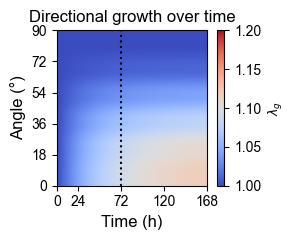

In [15]:
# # import numpy as np
# # import matplotlib.pyplot as plt

# # -----------------------------------------
# # USER CHOICE
# # -----------------------------------------
# T_run = 168          # change to 72 if desired

# # Fixed color scale so 72 h and 168 h runs are comparable
# vmax_fixed = 1.40    # adjust if you know your data exceed this

# # -----------------------------------------
# # Pick one representative experiment
# # -----------------------------------------
#     raise ValueError(f"No experiment found for time {sample_time} h")

# # -----------------------------------------
# # Run theta model continuously until T_run
# # -----------------------------------------
#     params,
# )

# # -----------------------------------------
# # Angle vector
# # -----------------------------------------

# # Keep only 0–90 deg for plotting if desired

# # -----------------------------------------
# # Heatmap
# # -----------------------------------------

#     lamg_plot.T,
# )

# # choose x ticks depending on run length

# -----------------------------------------
# USER CHOICE
# -----------------------------------------
sample = 14           # explicit dataset index
T_run = 168          # change to 72 if desired
n_theta = 10
dt = 0.1

# Fixed color scale so 72 h and 168 h runs are comparable
vmin_fixed = 1.0
vmax_fixed = 1.20    # adjust if needed

# -----------------------------------------
# Pick one experiment by explicit index
# -----------------------------------------
if sample < 0 or sample >= len(data["time_g1"]):
    raise ValueError(f"sample must be between 0 and {len(data['time_g1'])-1}")

i = int(sample)

lam1_exp  = float(data["G2_in_all"][i])
lamp1_exp = float(data["G2p_all"][i])
t_exp     = float(data["time_g2"][i])

print("Selected sample index:", i)
print("Experiment endpoint:", t_exp)
print("lam1_exp =", lam1_exp)
print("lamp1_exp =", lamp1_exp)
print("Simulation run until:", T_run)

# -----------------------------------------
# Run theta model continuously until T_run
# -----------------------------------------
#     params,
# )
results = run_simulation_constant_F_theta_local_signal(
params,
lam1=lam1_exp,
lamp1=lamp1_exp,
T_end=T_run,
dt=0.1,
n_theta=10,
lam2=1.0,
lamp2=1.0,
prestretch_side="right",
)

t_arr    = results[0]
lamg_G1  = results[1]
lamg_arr = results[2]   # shape = (time, angle)
lam_arr  = results[3]
lame_arr = results[4]

# -----------------------------------------
# Angle vector
# -----------------------------------------
theta_vals = np.linspace(0.0, np.pi, n_theta, endpoint=False)
theta_deg = np.degrees(theta_vals)

# Keep only 0–90 deg for plotting
theta_deg_plot = theta_deg[:6]
lamg_plot = lamg_arr[:, :6]

# -----------------------------------------
# Heatmap
# -----------------------------------------
plt.figure(figsize=(3, 2.5))

im = plt.imshow(
    lamg_plot.T,
    aspect="auto",
    origin="lower",
    extent=[t_arr[0], t_arr[-1], theta_deg_plot[0], theta_deg_plot[-1]],
    cmap="coolwarm",
    vmin=vmin_fixed,
    vmax=vmax_fixed
)
cbar = plt.colorbar(im, label=r"$\lambda_g$", location="right")
# cbar.set_label(r"$\lambda_g$", labelpad=1)  # Adjust labelpad to change the label position
cbar.ax.yaxis.label.set_size(9)

# vertical reference line at 72 h
plt.axvline(72, color="k", linestyle=":", linewidth=1.5)

plt.xlabel("Time (h)")
plt.ylabel("Angle (°)")
plt.yticks(theta_deg_plot)

# choose x ticks depending on run length
if T_run <= 72:
    plt.xticks([0, 24, 48, 72])
else:
    plt.xticks([0, 24, 72, 120, 168])

plt.title(f"Directional growth over time")
plt.tight_layout()
plt.savefig("figures_coupling_G2/directional_growth_heatmap_angTime.png", dpi=300)
plt.show()

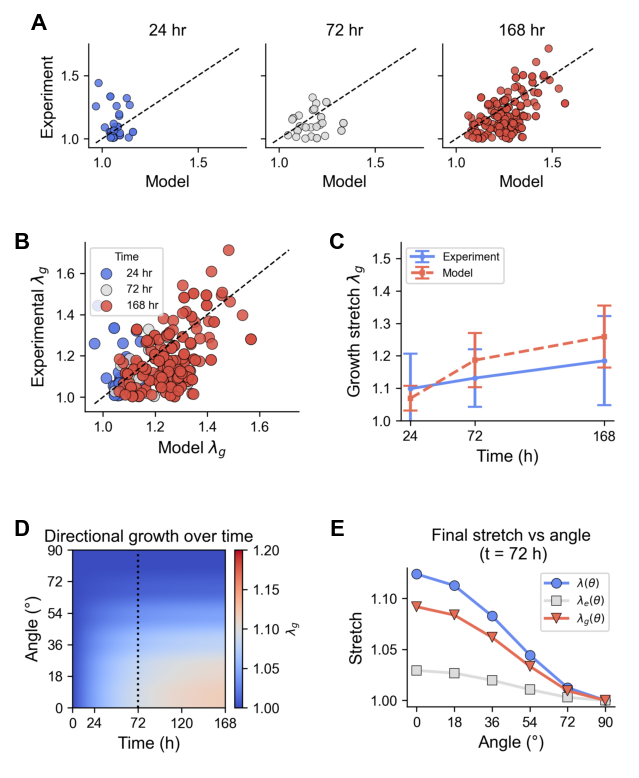

In [16]:

# # ---------------------------------
# # File names
# # ---------------------------------

# # ---------------------------------
# # Load images
# # ---------------------------------

# # ---------------------------------
# # Create combined figure
# # ---------------------------------
# # fig.subplots_adjust(left=0, right=1, top=1, bottom=0)

# # Top panel spans both columns

# # Bottom 2x2 grid

# # Optional panel labels

# # Save

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.gridspec import GridSpec

# ---------------------------------
# File names
# ---------------------------------
img_top = "figures_coupling_G2/model_vs_experiment_scatter_3.png"

img_1 = "figures_coupling_G2/model_vs_experiment_scatter.png"
img_2 = "figures_coupling_G2/growth_comparison_errorbar.png"
img_4 = "figures_coupling_G2/final_stretch_vs_angle_sample.png"
img_3 = "figures_coupling_G2/directional_growth_heatmap_angTime.png"

# ---------------------------------
# Load images
# ---------------------------------
top = mpimg.imread(img_top)
im1 = mpimg.imread(img_1)
im2 = mpimg.imread(img_2)
im3 = mpimg.imread(img_3)
im4 = mpimg.imread(img_4)

# ---------------------------------
# Create combined figure
# ---------------------------------
fig = plt.figure(figsize=(8,10))

gs = GridSpec(
    3, 2,
    figure=fig,
    height_ratios=[0.71, 1, 1],   # shrink vertical size of top row
    hspace=0.04,
    wspace=0.04
)

# ---------------------------------
# Top panel
# ---------------------------------
ax_top = fig.add_subplot(gs[0, :])
ax_top.imshow(top)
ax_top.axis("off")

# ---------------------------------
# Bottom 2x2 grid
# ---------------------------------
ax1 = fig.add_subplot(gs[1, 0])
ax1.imshow(im1)
ax1.axis("off")

ax2 = fig.add_subplot(gs[1, 1])
ax2.imshow(im2)
ax2.axis("off")

ax3 = fig.add_subplot(gs[2, 0])
ax3.imshow(im3)
ax3.axis("off")

ax4 = fig.add_subplot(gs[2, 1])
ax4.imshow(im4)
ax4.axis("off")

# ---------------------------------
# Panel labels
# ---------------------------------
ax_top.text(0.01,0.98,"A",transform=ax_top.transAxes,
            fontsize=16,fontweight="bold",va="top")
ax1.text(0.01,0.98,"B",transform=ax1.transAxes,
         fontsize=16,fontweight="bold",va="top")
ax2.text(0.01,0.98,"C",transform=ax2.transAxes,
         fontsize=16,fontweight="bold",va="top")
ax3.text(0.01,0.98,"D",transform=ax3.transAxes,
         fontsize=16,fontweight="bold",va="top")
ax4.text(0.01,0.98,"E",transform=ax4.transAxes,
         fontsize=16,fontweight="bold",va="top")

# ---------------------------------
# Save
# ---------------------------------
plt.savefig(
    "figures_coupling_G2/combined_calibration_figure_G2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:


#     lambdae,
#     growth_rate,
# )



In [18]:
## SENSITIVITY ANALYSIS

In [19]:
# =========================================
# 1️⃣ Define baseline parameter vector
# =========================================
theta_base = np.array([
    params["a"],
    params["b"],
    params["c"],
    params["d"],
    params["tau_g"]
])

param_names = ["a", "b", "c", "d", "tau_g"]

# =========================================
# 2️⃣ Function to compute loss for a theta
# =========================================
def compute_loss(theta_vec):
    test_params = {
        "a": theta_vec[0],
        "b": theta_vec[1],
        "c": theta_vec[2],
        "d": theta_vec[3],
        "tau_g": theta_vec[4]
    }

    loss = 0.0

    for i in arr:
        theta_exp  = data["G2_in_all"][i]
        thetap_exp = data["G2p_all"][i]
        thetag_exp = data["G2g_all"][i]
        t_exp      = data["time_g2"][i]

        results = run_simulation_constant_F(
            test_params,
            theta_exp,
            thetap_exp,
            T_end=t_exp,
            dt=0.1
        )

        thetag_model = results[1][-1]
        loss += (thetag_model - thetag_exp)**2

    return loss


# =========================================
# 3️⃣ Sensitivity Sweep
# =========================================
perturb_fraction = 0.5   # ±50% variation
n_points = 25            # resolution of sweep

plt.figure(figsize=(12,8))

for j in range(len(theta_base)):

    base_value = theta_base[j]

    # Avoid zero-centered scaling issues
    if base_value == 0:
        sweep = np.linspace(-1, 1, n_points)
    else:
        sweep = np.linspace(
            base_value*(1 - perturb_fraction),
            base_value*(1 + perturb_fraction),
            n_points
        )

    losses = []

    for val in sweep:
        theta_test = theta_base.copy()
        theta_test[j] = val
        L = compute_loss(theta_test)
        losses.append(L)

    losses = np.array(losses)

    plt.subplot(3,2,j+1)
    plt.plot(sweep, losses, '-o')
    plt.axvline(base_value, color='red', linestyle='--')
    plt.title(f"Sensitivity of {param_names[j]}")
    plt.xlabel(param_names[j])
    plt.ylabel("Loss")
    plt.yscale("log")
    plt.grid(True)

plt.tight_layout()
plt.show()


IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

<Figure size 1200x800 with 0 Axes>

In [ ]:
## READ SENSITIVITY RESULTS

In [ ]:
df = pd.read_csv("sensitivity_analysis_data.csv")

param_names = df["parameter"].unique()

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)

for i, param_name in enumerate(param_names):
    subset = df[df["parameter"] == param_name]
    axes[i].plot(subset["x_value"], subset["loss"])
    axes[i].set_xlabel(param_name)
    axes[i].set_ylabel("Loss")
    axes[i].set_title(f"{param_name} Sensitivity")
    axes[i].grid(True)

plt.tight_layout()
plt.show()


In [1]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.integrate import ode 
from scipy.optimize import minimize
import csv
import itertools
import pandas as pd
import seaborn as sns
from model_DOF_clustering_5 import objective_function, load_ko_and_expectation_data, wlen, family_id_vector, build_weight_vector, run_model_real
from coupling_G1_optimizer import load_growth_csv, build_observed_dataset, summarize_by_time, filter_growth_below_one, mech_to_signal1, CI_to_phi_a, deriv_after_mech_change, update_Fg, run_simulation_constant_F, loss_function, callback_loss

In [2]:
data1 = build_observed_dataset(
    "Iso_data_4_pigs.csv",
    "Iso_data_4_pigs_G1.csv",
    "Iso_data_4_pigs_G2.csv",
)
data = filter_growth_below_one(data1, tol=1e-6)

In [3]:
# %%
# -------------------------------------------------
# INITIAL PARAMETER GUESS
# -------------------------------------------------
params = {
    "a": 1.0, "b": 0.0,   # CI → growth in G1
    # "e": 1.0, "f": 0.0,   # CI → growth in G2
    "c": 1.0, "d": 0.0,   # theta_e → signaling
    # "g": 1.0, "h": 0.0,   # theta_e → signaling
    "tau_g": 0.5,
    # "tau_s": 0.5,
    # "tau_w": 1.0,
    # "tau_k": 1.0,
    # "gamma_k": 1.0
}

theta0 = np.array([
    params["a"],
    params["b"],
    params["c"],
    params["d"],
    params["tau_g"],
    # params["e"],
    # params["f"],
    # params["g"],
    # params["h"]
])

In [4]:
G1_all=data["G1_in_all"]
G1p_all=data["G1p_all"]
print(np.size(G1p_all))

273


In [5]:
print(len(data["time_g1"]))

273


In [11]:
import time

t0 = time.time()
L = loss_function(theta0, data)
dt_loss = time.time() - t0

print(f"Loss: {L:.3e}")
print(f"Total loss time: {dt_loss:.3f} s")
print(f"Time per simulation: {dt_loss / n_runs:.3f} s")


Loss: 9.587e-03
Total loss time: 11.323 s
Time per simulation: 5.661 s
